<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Praktikum_2_ML_CRISP_DM_Bias_Variance_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Machine Learning: CRISP-DM & Diagnosis Bias-Variance
**Studi kasus:** Prediksi Churn Pelanggan Telekomunikasi (Telco Customer Churn)

- **Praktikum 1** – Pemetaan proyek ke 6 fase CRISP-DM
- **Praktikum 2** – Learning curve & diagnosis bias-variance (`max_depth` = 1, 4, None)

## Praktikum 1: Memetakan Proyek ke CRISP-DM

### Fase 1 – Business Understanding
- **Masalah bisnis:** perusahaan telekomunikasi kehilangan pelanggan (churn), dan biaya mencari pelanggan baru lebih mahal daripada mempertahankan yang lama.
- **Tujuan bisnis:** mengurangi tingkat churn lewat program retensi yang tepat sasaran.
- **Tujuan data mining:** membangun model klasifikasi biner (`Churn` = Yes/No) untuk mengidentifikasi pelanggan berisiko churn.
- **Kriteria sukses:** model mampu mengenali pelanggan churn dengan baik (recall/F1 kelas churn), bukan hanya akurasi tinggi.

### Fase 2 – Data Understanding
- Mengumpulkan data: dataset Telco Customer Churn (Kaggle), 7.043 pelanggan dan 21 kolom.
- Mengecek tipe data, nilai kosong, dan statistik deskriptif.
- Mengecek distribusi target: ±73,5% tidak churn vs ±26,5% churn (**imbalanced**).
- Eksplorasi hubungan fitur dengan churn (misalnya `Contract`, `tenure`, `MonthlyCharges`).
- Menemukan masalah kualitas data: kolom `TotalCharges` bertipe teks dan ada 11 nilai kosong (spasi).

### Fase 3 – Data Preparation
- Menghapus kolom `customerID` (hanya identitas, tidak informatif).
- Mengubah `TotalCharges` ke numerik dan mengisi 11 nilai kosong dengan 0 (pelanggan baru, `tenure` = 0).
- Mengubah target `Churn` menjadi 0/1.
- Encoding fitur kategorikal dengan one-hot encoding.
- Split data train/test 80:20 dengan **stratified split** agar proporsi churn terjaga.

### Fase 4 – Modeling
- Memilih algoritma: Decision Tree Classifier (mudah diinterpretasi).
- Melatih model dengan beberapa kompleksitas (`max_depth` = 1, 4, None).
- Membuat learning curve dengan 5-fold cross-validation untuk melihat bias-variance.
- Opsional: tuning hyperparameter (GridSearchCV) dan mencoba model lain (Random Forest, Logistic Regression).

### Fase 5 – Evaluation
- Mengevaluasi model terpilih pada **test set** (accuracy, precision, recall, F1, confusion matrix).
- Karena data imbalanced, fokus ke recall/F1 kelas churn.
- Mengecek apakah model memenuhi kriteria sukses fase 1 dan memeriksa gap train vs validasi.
- Meninjau ulang apakah semua tujuan bisnis sudah tercakup sebelum deployment.

### Fase 6 – Deployment
- Menyimpan model (misalnya dengan `joblib`) dan membuat pipeline prediksi untuk data pelanggan baru.
- Mengintegrasikan ke sistem (dashboard/API) agar tim marketing mendapat daftar pelanggan berisiko churn.
- Monitoring performa model secara berkala dan melatih ulang bila terjadi data drift.
- Membuat dokumentasi dan laporan akhir.

## Praktikum 2: Diagnosis Bias-Variance
### 2.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

### 2.2 Import Dataset
Jalankan sel ini lalu **upload** file `WA_Fn-UseC_-Telco-Customer-Churn.csv` (atau taruh di Google Drive).

In [2]:
from google.colab import files
uploaded = files.upload()   # pilih file CSV Telco

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Cek data (Data Understanding)
df.info()
print("\nNilai kosong:", df.isna().sum().sum())
print("Distribusi kelas:\n", df['Churn'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 2.3 Preprocessing & Stratified Split

In [4]:
# TotalCharges bertipe teks, ada 11 baris berisi spasi -> jadikan numerik
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df = df.drop(columns='customerID')

y = (df['Churn'] == 'Yes').astype(int)
X = pd.get_dummies(df.drop(columns='Churn'), drop_first=True)
print("Bentuk X:", X.shape)
print("Distribusi kelas:", np.bincount(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Proporsi kelas train:", np.bincount(y_train) / len(y_train))
print("Proporsi kelas test :", np.bincount(y_test) / len(y_test))

Bentuk X: (7043, 30)
Distribusi kelas: [5174 1869]
Proporsi kelas train: [0.73464679 0.26535321]
Proporsi kelas test : [0.73456352 0.26543648]


### 2.4 Training Model & Learning Curve (max_depth = 4)

In [5]:
model = DecisionTreeClassifier(max_depth=4, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train, y_train,
    cv=5, train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="accuracy")

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

### 2.5 Evaluasi

In [6]:
print("Skor train pada ukuran data terbesar :", round(train_mean[-1], 3))
print("Skor validasi pada ukuran data terbesar:", round(val_mean[-1], 3))
print("Gap (indikasi overfitting jika besar)  :", round(train_mean[-1] - val_mean[-1], 3))

Skor train pada ukuran data terbesar : 0.797
Skor validasi pada ukuran data terbesar: 0.782
Gap (indikasi overfitting jika besar)  : 0.015


### 2.6 Visualisasi

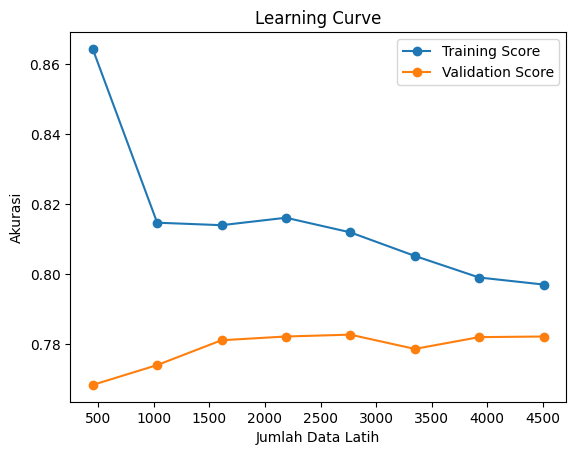

In [7]:
plt.plot(train_sizes, train_mean, 'o-', label='Training Score')
plt.plot(train_sizes, val_mean, 'o-', label='Validation Score')
plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve')
plt.legend()
plt.show()

### 2.7 Bandingkan Learning Curve untuk `max_depth` Berbeda

max_depth=1: train=0.744, val=0.727, gap=0.017
max_depth=4: train=0.818, val=0.781, gap=0.037
max_depth=None: train=0.999, val=0.728, gap=0.272


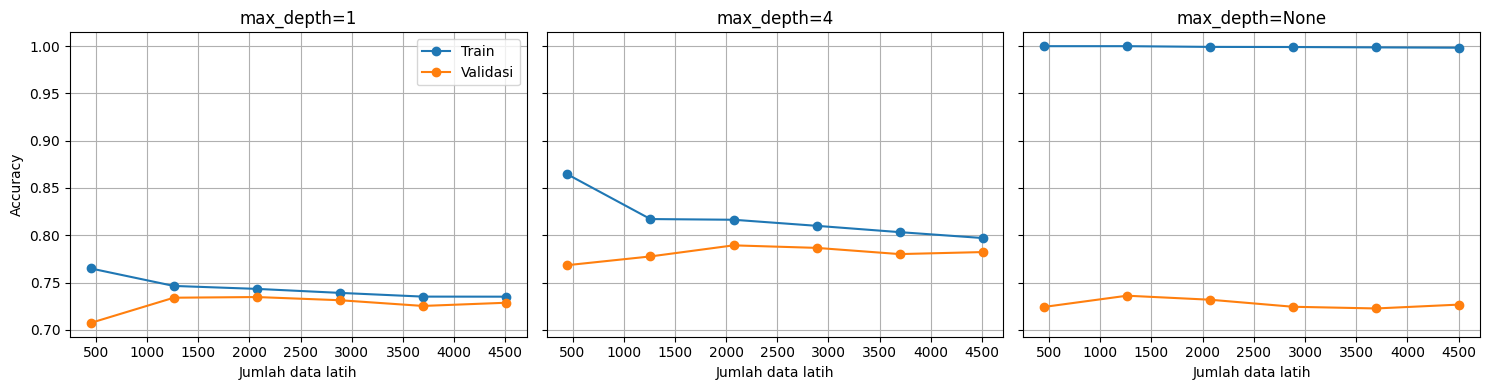

In [8]:
depths = [1, 4, None]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, depth in zip(axes, depths):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=5, train_sizes=np.linspace(0.1, 1.0, 6))
    print(f"max_depth={depth}: train={train_scores.mean():.3f}, "
          f"val={val_scores.mean():.3f}, gap={train_scores.mean()-val_scores.mean():.3f}")

    ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train')
    ax.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validasi')
    ax.set_title(f'max_depth={depth}')
    ax.set_xlabel('Jumlah data latih'); ax.grid(True)
axes[0].set_ylabel('Accuracy'); axes[0].legend()
plt.tight_layout(); plt.show()

### Diagnosis

| max_depth | Train | Validasi | Gap | Diagnosis |
|---|---|---|---|---|
| 1 | ≈ 0,744 | ≈ 0,727 | kecil (≈ 0,017) | **Underfitting** (high bias) |
| 4 | ≈ 0,818 | ≈ 0,781 | sedang (≈ 0,037) | **Seimbang** (good fit) |
| None | ≈ 0,999 | ≈ 0,728 | sangat besar (≈ 0,27) | **Overfitting** (high variance) |



**Penjelasan:**
- **max_depth=1** – pohon hanya punya satu pemisahan, terlalu sederhana untuk menangkap pola churn. Skor train dan validasi sama-sama rendah dan berdekatan (gap kecil tapi performa rendah), jadi bias tinggi. Akurasinya hampir sama dengan menebak semua pelanggan "tidak churn" (±73,5%).
- **max_depth=4** – skor validasi paling tinggi dengan gap train-validasi yang wajar. Model punya keseimbangan bias-variance yang baik dan siap dievaluasi di test set.
- **max_depth=None** – pohon tumbuh sampai menghafal data latih (train ≈ 100%), tetapi skor validasi turun karena tidak mampu generalisasi. Gap besar menandakan varians tinggi. Solusinya: batasi `max_depth`, pruning, atau tambah data latih.

### Evaluasi Akhir pada Test Set (model terbaik: max_depth=4)

In [9]:
best = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
y_pred = best.predict(X_test)
print("Accuracy test:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred, target_names=['Tidak churn', 'Churn']))

Accuracy test: 0.796
              precision    recall  f1-score   support

 Tidak churn       0.84      0.90      0.87      1035
       Churn       0.64      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

